In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch.nn as nn
from torch.utils.data import DataLoader,Dataset
import torch.optim as optim
import matplotlib.pyplot as plt
import torch

In [2]:
torch.manual_seed(42)

In [22]:
device = torch.device('cuda')

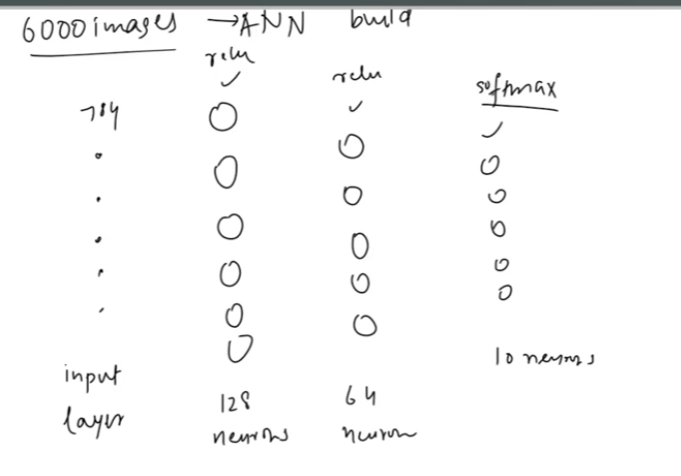

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


In [5]:
import shutil

destination = "/content/FashionMNIST"

shutil.copytree(path, destination, dirs_exist_ok=True)

print("Dataset saved to Google Drive:", destination)

Dataset saved to Google Drive: /content/FashionMNIST


In [6]:
df = pd.read_csv('/content/FashionMNIST/fashion-mnist_train.csv')

In [7]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:

df.shape

(60000, 785)

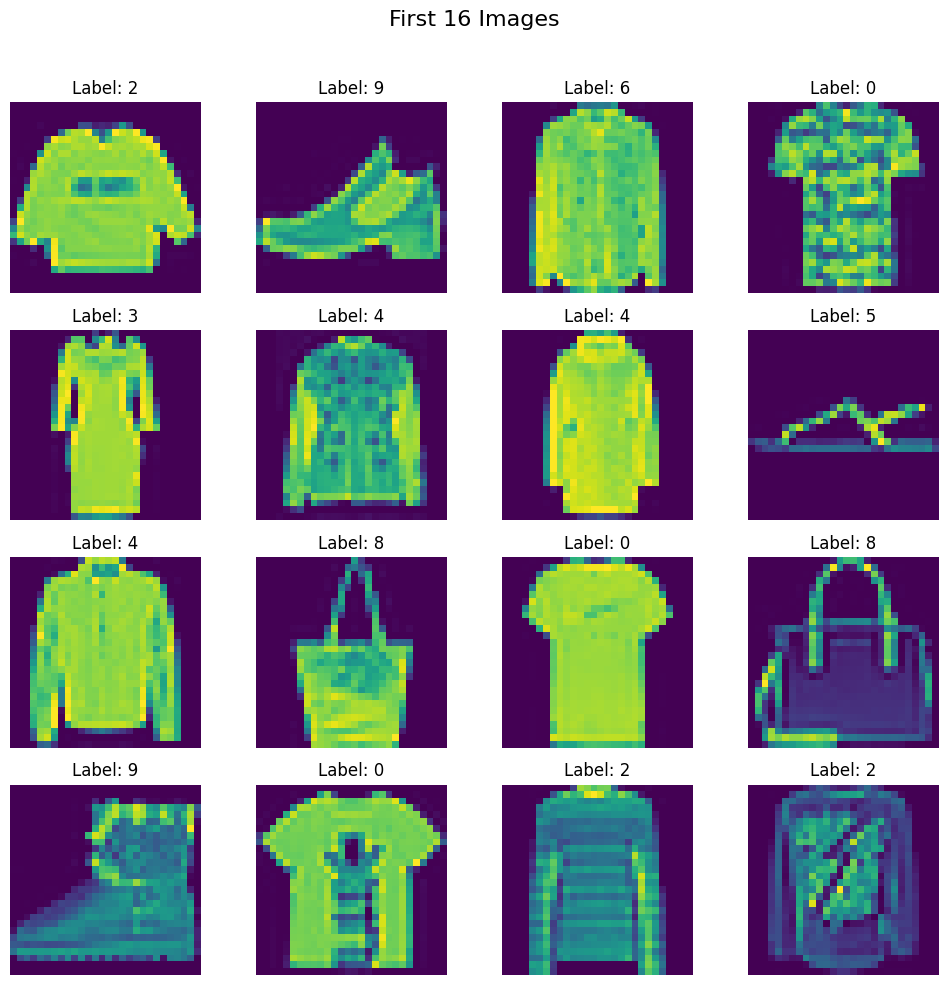

In [9]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()


In [10]:
x = df.iloc[:,1:].values
y = df.iloc[:,0:1].values

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [12]:
x_train.shape

(48000, 784)

In [13]:
# feature scalling
x_train = x_train/255.0
x_test = x_test/255.0

# The Class Declaration: class customDataset(Dataset):

• What it does: This defines your new dataset type.
• The parent (Dataset): This tells Python that your class inherits from PyTorch's built-in Dataset utility. By doing this, your custom dataset automatically becomes compatible with PyTorch's DataLoader (which handles shuffling, batching, and multiprocessing for your model).


# 1. The Initialization Function: __init__(self, features, leables):

• Purpose: This function runs automatically the exact moment you create your dataset (e.g., when you write dataset = customDataset(X, y)). It acts as the setup manager.
• self.features = torch.tensor(...): It takes your raw input data (like images, text arrays, or numbers) and converts them into a PyTorch Float32 Tensor so the neural network can run math calculations on it.
• self.leables = torch.tensor(...): It takes your target answers (labels) and converts them into a PyTorch Long Tensor (integers). This is the standard data type PyTorch expects for classification categories.

# 2. The Length Function: __len__(self):

• Purpose: This tells PyTorch exactly how many items are inside your dataset.

# 3. The Item Retrieval Function: __getitem__(self, index):

• Purpose: This allows you to pull out a single data point and its matching label using an index number (e.g., dataset[5]).

In [14]:
# create a customDataset class
class customDataset(Dataset):
  def __init__(self, features, leables):
    self.features = torch.tensor(features, dtype = torch.float32)
    self.leables = torch.tensor(leables, dtype = torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index], self.leables[index]

In [15]:
# create train dataset
train_dataset = customDataset(x_train, y_train)

In [16]:
# create test dataset
test_dataset = customDataset(x_test, y_test)

In [17]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [18]:
train_dataset[0]

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2275,
         0.5333, 0.0000, 0.0

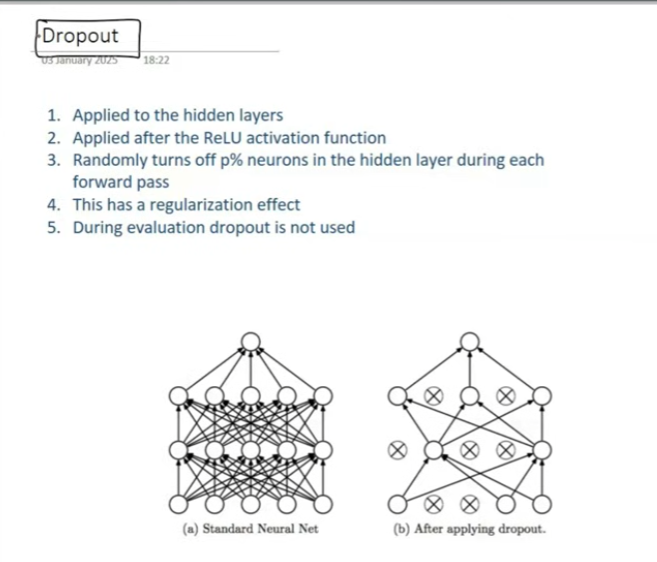

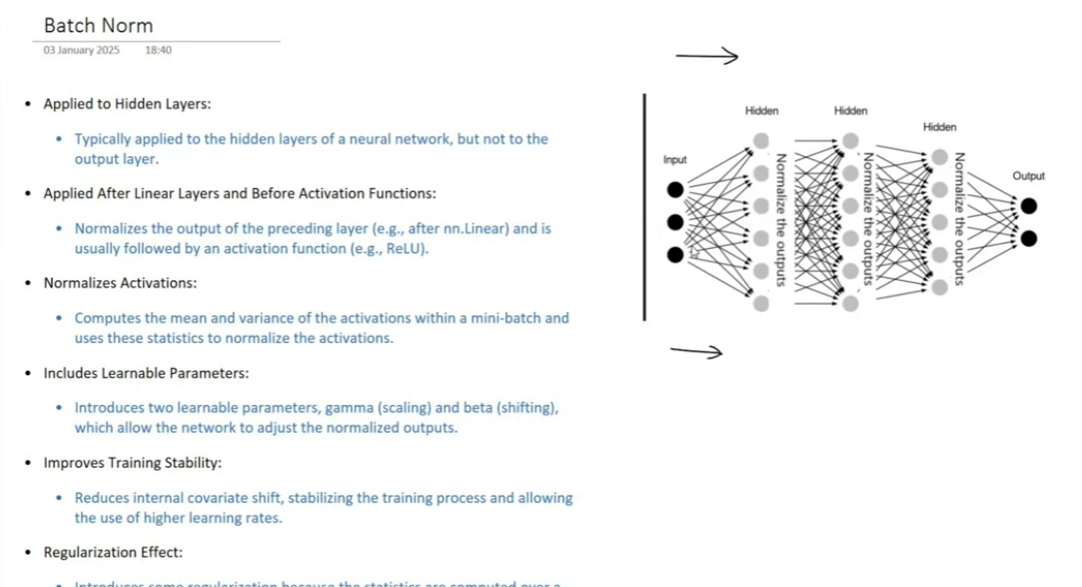

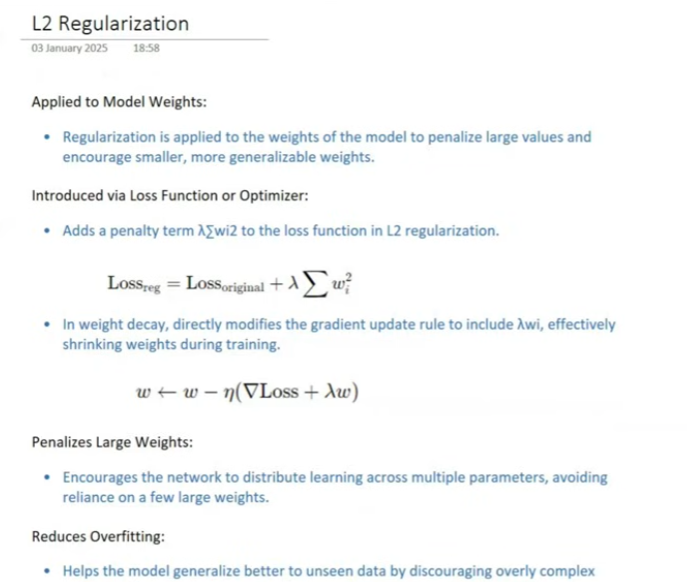

In [19]:
# define NN class

class MyNN(nn.Module):

  def __init__(self, num_features):

    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(p=0.3),
        nn.Linear(128, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(p=0.3),
        nn.Linear(64, 10)
    )

  def forward(self, x):

    return self.model(x)

In [20]:
# set learning rate and epochs
epochs = 100
learning_rate = 0.1

In [28]:
# instanciate the class
model = MyNN(x_train.shape[1])
model = model.to(device)
# Loss function
loss_function = nn.CrossEntropyLoss()

# optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=1e-4)

In [27]:
torch.cuda.is_available()

False

In [31]:
# training loop
for epoch in range(epochs):
    total_epochs_loss = 0

    for batch_features, batch_label in train_loader:
        # Move batches to your device (CPU or GPU)
        batch_features = batch_features.to(device)
        batch_label = batch_label.to(device)

        # Forward pass
        outputs = model(batch_features)

        # Calculate loss
        loss = loss_function(outputs, batch_label.flatten())

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update parameters
        optimizer.step()

        total_epochs_loss += loss.item()

    avg_loss = total_epochs_loss / len(train_loader)
    print(f'Epoch: {epoch+1}, Loss: {avg_loss:.4f}')


Epoch: 1, Loss: 0.6290
Epoch: 2, Loss: 0.5026
Epoch: 3, Loss: 0.4592
Epoch: 4, Loss: 0.4335
Epoch: 5, Loss: 0.4175
Epoch: 6, Loss: 0.4006
Epoch: 7, Loss: 0.3923
Epoch: 8, Loss: 0.3814
Epoch: 9, Loss: 0.3749
Epoch: 10, Loss: 0.3666
Epoch: 11, Loss: 0.3601
Epoch: 12, Loss: 0.3568
Epoch: 13, Loss: 0.3587
Epoch: 14, Loss: 0.3431
Epoch: 15, Loss: 0.3432
Epoch: 16, Loss: 0.3387
Epoch: 17, Loss: 0.3388
Epoch: 18, Loss: 0.3344
Epoch: 19, Loss: 0.3249
Epoch: 20, Loss: 0.3283
Epoch: 21, Loss: 0.3271
Epoch: 22, Loss: 0.3177
Epoch: 23, Loss: 0.3173
Epoch: 24, Loss: 0.3143
Epoch: 25, Loss: 0.3090
Epoch: 26, Loss: 0.3123
Epoch: 27, Loss: 0.3083
Epoch: 28, Loss: 0.3087
Epoch: 29, Loss: 0.3065
Epoch: 30, Loss: 0.3043
Epoch: 31, Loss: 0.3056
Epoch: 32, Loss: 0.3003
Epoch: 33, Loss: 0.2999
Epoch: 34, Loss: 0.2927
Epoch: 35, Loss: 0.2994
Epoch: 36, Loss: 0.2982
Epoch: 37, Loss: 0.2958
Epoch: 38, Loss: 0.2973
Epoch: 39, Loss: 0.2923
Epoch: 40, Loss: 0.2898
Epoch: 41, Loss: 0.2921
Epoch: 42, Loss: 0.2901
E

In [32]:
# evulation code
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [34]:
# evaluation code
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move batches to GPU
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels.flatten()).sum().item()

print(correct/total)

0.8929166666666667


In [35]:
len(test_loader)

375

In [36]:
len(train_loader)

1500

# Solving the problem of Overfitting

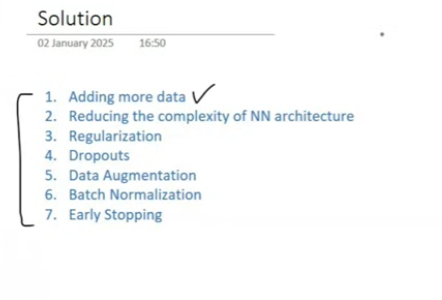